# 01 — OpenCV Fundamentals

A practical introduction to reading, inspecting, displaying, saving, and manipulating images with OpenCV.

**Focus:** OpenCV API + NumPy image representation.  
**Style:** Short explanations, small examples, and important details only.

## 1. Setup

Install OpenCV if it is not already available.

For desktop/image processing:

In [1]:
# Run once if needed
# !pip install opencv-python numpy

In [2]:
import cv2
import numpy as np

print("OpenCV:", cv2.__version__)
print("NumPy:", np.__version__)

OpenCV: 4.13.0
NumPy: 2.2.6


## 2. Reading an Image

`cv2.imread()` loads an image and returns it as a NumPy array.

By default, a color image is loaded in **BGR** order.

In [3]:
image = cv2.imread("cat.jpg")

print(type(image))
print(image.shape)

<class 'numpy.ndarray'>
(350, 525, 3)


### Check Whether Loading Succeeded

If the path is wrong or the file cannot be decoded, `imread()` returns `None`.

In [4]:
image = cv2.imread("cat.jpg")

if image is None:
    print("Image could not be loaded.")
else:
    print("Image loaded successfully.")

Image loaded successfully.


## 3. `cv2.imread()` Modes

The second argument controls how the image is loaded.

- `cv2.IMREAD_COLOR` → 3-channel BGR image
- `cv2.IMREAD_GRAYSCALE` → 1-channel grayscale image
- `cv2.IMREAD_UNCHANGED` → keeps available channels, including alpha

In [5]:
color = cv2.imread("cat.jpg", cv2.IMREAD_COLOR)
gray = cv2.imread("cat.jpg", cv2.IMREAD_GRAYSCALE)
unchanged = cv2.imread("cat.png", cv2.IMREAD_UNCHANGED)

print("Color:", color.shape)
print("Gray:", gray.shape)
# print("Unchanged:", unchanged.shape)  # this image dont have alpha

Color: (350, 525, 3)
Gray: (350, 525)


## 4. Image as a NumPy Array

OpenCV images are NumPy arrays.

For a color image:

\[
	shape = (H, W, C)
\]

where `H` = height, `W` = width, and `C` = number of channels.

In [6]:
height, width, channels = image.shape

print("Height:", height)
print("Width:", width)
print("Channels:", channels)
print("Shape:", image.shape)
print("Data type:", image.dtype)

Height: 350
Width: 525
Channels: 3
Shape: (350, 525, 3)
Data type: uint8


## 5. Pixel Values

A pixel is accessed using:

```python
image[y, x]
```

OpenCV/NumPy uses **row, column** indexing, so `y` comes before `x`.

In [7]:
pixel = image[100, 200]

print("Pixel:", pixel)

Pixel: [ 60 194 206]


### Access One Channel

For a BGR image:

```text
channel 0 → Blue
channel 1 → Green
channel 2 → Red
```

In [8]:
blue = image[100, 200, 0]
green = image[100, 200, 1]
red = image[100, 200, 2]

print("B:", blue)
print("G:", green)
print("R:", red)

B: 60
G: 194
R: 206


## 6. Pixel Value Range

For the common `uint8` image format, each channel stores an integer from **0 to 255**.

`0` represents minimum intensity and `255` represents maximum intensity.

In [9]:
print("Minimum:", image.min())
print("Maximum:", image.max())
print("Data type:", image.dtype)

Minimum: 0
Maximum: 255
Data type: uint8


## 7. BGR vs RGB

OpenCV normally stores color channels as:

\[
[B, G, R]
\]

Many other libraries use:

\[
[R, G, B]
\]

This difference matters whenever an image moves between libraries.

In [10]:
rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

print("OpenCV pixel:", image[100, 200])
print("RGB pixel:", rgb[100, 200])

OpenCV pixel: [ 60 194 206]
RGB pixel: [206 194  60]


## 8. Displaying an Image

`cv2.imshow()` creates a native OpenCV window.

`waitKey()` keeps the window alive and allows keyboard input.

In [11]:
cv2.imshow("Image", image)
cv2.waitKey(0)
cv2.destroyAllWindows()

In [12]:
cv2.imshow("Image", rgb)
cv2.waitKey(0)
cv2.destroyAllWindows()

### Important

`cv2.imshow()` is designed for a desktop GUI environment.

In some Jupyter/Colab environments, use Matplotlib for display instead.

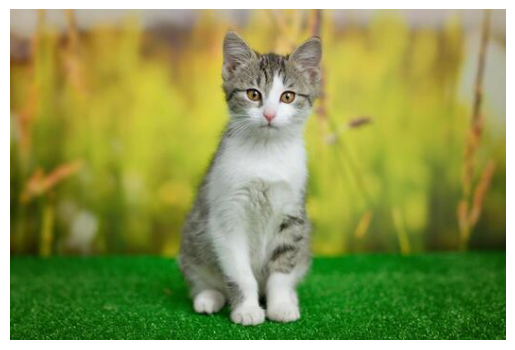

In [13]:
import matplotlib.pyplot as plt

plt.imshow(rgb)
plt.axis("off")
plt.show()

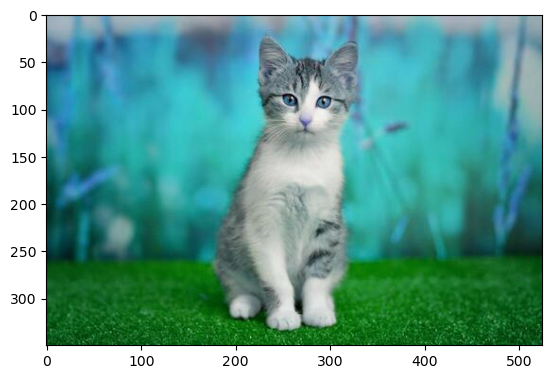

In [14]:
plt.imshow(image)
plt.show()

## 9. Saving an Image

`cv2.imwrite()` writes the NumPy image array to a file.

It returns `True` when the write succeeds.

In [15]:
success = cv2.imwrite("cat_copy.jpg", image)

print("Saved:", success)

Saved: True


## 10. Grayscale

A grayscale image has one intensity value per pixel instead of three color channels.

For an 8-bit grayscale image:

\[
	shape = (H, W)
\]

and each pixel is in the range `0–255`.

In [16]:
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

print("Shape:", gray.shape)
print("Data type:", gray.dtype)
print("Pixel:", gray[100, 200])

Shape: (350, 525)
Data type: uint8
Pixel: 182


## 11. Channel Splitting

A BGR image can be separated into three 2D arrays.

Each channel has the same height and width as the original image.

In [17]:
b, g, r = cv2.split(image)

print("Blue:", b.shape)
print("Green:", g.shape)
print("Red:", r.shape)

Blue: (350, 525)
Green: (350, 525)
Red: (350, 525)


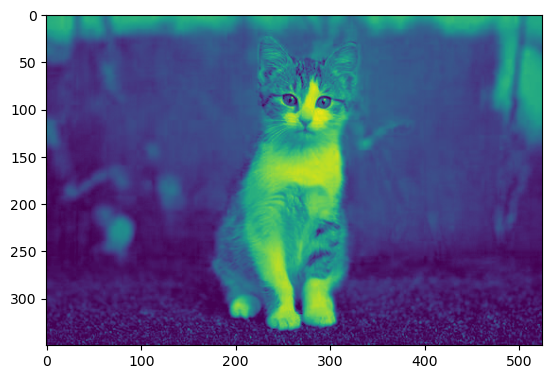

In [18]:
plt.imshow(b)
plt.show()

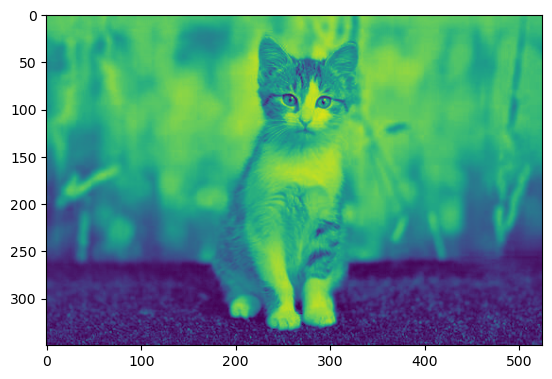

In [19]:
plt.imshow(r)

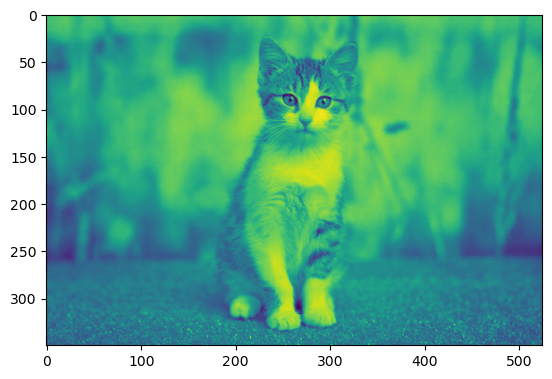

In [20]:
plt.imshow(g)

## 12. Channel Merging

`cv2.merge()` combines separate channel arrays into one multi-channel image.

The channel order determines the resulting color representation.

In [21]:
merged = cv2.merge([b, g, r])

print(merged.shape)

(350, 525, 3)


## 13. Copying an Image

This is important because assigning an array does **not** create a separate image.

Use `.copy()` when you need an independent copy.

In [22]:
same_image = image
copied_image = image.copy()

copied_image[100, 100] = [0, 0, 255]

print("Original:", image[100, 100])
print("Copy:", copied_image[100, 100])

Original: [ 51 174 188]
Copy: [  0   0 255]


## 14. Basic Image Statistics

NumPy operations can quickly describe an image.

Useful operations include `min()`, `max()`, `mean()`, and `std()`.

In [23]:
print("Min:", image.min())
print("Max:", image.max())
print("Mean:", image.mean())
print("Standard deviation:", image.std())

Min: 0
Max: 255
Mean: 112.82190476190476
Standard deviation: 63.44475378442602


## 15. Image Properties Cheat Sheet

| Property | Meaning |
|---|---|
| `image.shape` | Dimensions |
| `image.dtype` | Data type |
| `image.min()` | Minimum value |
| `image.max()` | Maximum value |
| `image.mean()` | Average value |
| `image.size` | Number of array elements |
| `image.ndim` | Number of dimensions |

In [24]:
print("Shape:", image.shape)
print("Dimensions:", image.ndim)
print("Elements:", image.size)
print("Data type:", image.dtype)

Shape: (350, 525, 3)
Dimensions: 3
Elements: 551250
Data type: uint8


## 16. Accessing a Region

NumPy slicing can extract a rectangular region.

```python
image[y1:y2, x1:x2]
```

The upper limits are exclusive.

In [25]:
roi = image[100:300, 200:500]

print("ROI shape:", roi.shape)

cv2.imshow("ROI", roi)
cv2.waitKey(0)
cv2.destroyAllWindows()

ROI shape: (200, 300, 3)


## 17. Modifying a Region

Because an OpenCV image is a NumPy array, NumPy slicing can modify many pixels at once.

In [28]:
image_copy = image.copy()

image_copy[100:200, 200:400] = [0, 0, 255]

cv2.imshow("Modified", image_copy)
cv2.waitKey(0)
cv2.destroyAllWindows()

## 18. A Small Complete Example

Load → inspect → convert → display → save.

In [30]:
image = cv2.imread("cat.jpg")

if image is None:
    raise FileNotFoundError("Could not load cat.jpg")

print("Shape:", image.shape)
print("Type:", image.dtype)

gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

cv2.imwrite("cat_gray.jpg", gray)

cv2.imshow("Original", image)
cv2.imshow("Gray", gray)

cv2.waitKey(0)
cv2.destroyAllWindows()

Shape: (350, 525, 3)
Type: uint8


## 19. Common Mistakes

### BGR/RGB confusion
OpenCV uses BGR by default; displaying it through RGB-based libraries without conversion can produce incorrect colors.

### Wrong indexing
Use `image[y, x]`, not `image[x, y]`.

### Missing image check
Always check whether `imread()` returned `None` when the file path may be invalid.

### Accidental modification
Use `image.copy()` when the original array must remain unchanged.

# Summary

- OpenCV images are NumPy arrays.
- Color images commonly have shape `(H, W, 3)`.
- OpenCV uses BGR channel order.
- `image[y, x]` accesses a pixel.
- `uint8` images normally use values from `0–255`.
- Grayscale images have shape `(H, W)`.
- NumPy slicing handles regions and direct pixel manipulation.
- `imread → process → imwrite/imshow` is the basic OpenCV workflow.